In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
arm_borders = np.load("arm_borders.npy")

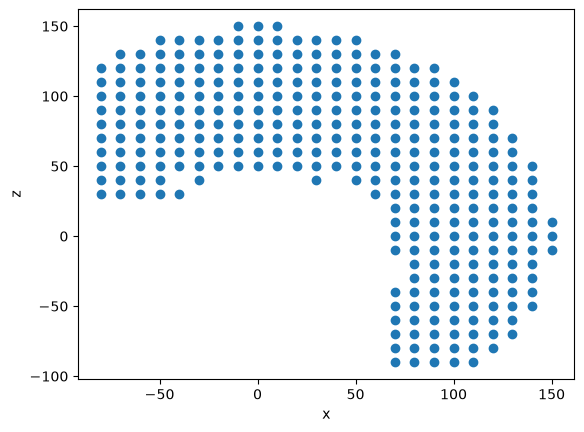

In [10]:
x = arm_borders[:, 0]
z = arm_borders[:, 1]
mask = (x > 50) | (z > 0)

x = x[mask]
z = z[mask]

plt.scatter(x, z)
plt.xlabel("x")
plt.ylabel("z")
plt.show()

In [1]:
import pandas as pd
import numpy as np

In [80]:
data_raw = pd.read_csv("arm_tag_pairs_10mm2.csv")
camera_columns = ["camera_x_mm", "camera_y_mm", "camera_z_mm"]
keys = ["arm_x", "arm_z", "tag_id"]
data = data_raw

# # Разделяем последовательные посещения до усреднения.
# visit_id = data_raw[keys].ne(data_raw[keys].shift()).any(axis=1).cumsum()
# visits = data_raw.groupby(visit_id, sort=False)
# averaged = visits[keys + camera_columns].mean()
# averaged["samples"] = visits.size()

# # Новый сборщик уже усреднил кадры: одна строка на положение.
# min_samples = 1
# min_movement_mm = 3.0
# last_position = None
# reasons = []
# for _, row in averaged.iterrows():
#     position = row[camera_columns].to_numpy(dtype=float)
#     if row["tag_id"] != 1:
#         reason = "other_tag"
#     elif not np.isfinite(row[keys + camera_columns].to_numpy(dtype=float)).all() or position[2] <= 0:
#         reason = "invalid_position"
#     elif row["samples"] < min_samples:
#         reason = "single_frame_manual_sample"
#     elif last_position is not None and np.linalg.norm(position - last_position) < min_movement_mm:
#         reason = "no_observed_movement"
#     else:
#         reason = "accepted"
#         last_position = position.copy()
#     reasons.append(reason)
# averaged["reason"] = reasons
# averaged.to_csv("arm_tag_pairs_10mm_filter_report.csv", index=False)
# data = averaged.loc[averaged["reason"] == "accepted", keys + camera_columns].reset_index(drop=True)
# data.to_csv("arm_tag_pairs_10mm_averaged.csv", index=False)
# print(averaged["reason"].value_counts().to_string())
# print(f"Для обучения: {len(data)} положений")
# data

In [81]:
R = np.array([
    [ 0,  0,  1],
    [-1,  0,  0],
    [ 0, -1,  0],
])

In [82]:
A = data[["arm_x", "arm_z"]].to_numpy()
A

array([[ 80.,  20.],
       [ 80.,  30.],
       [ 80.,  40.],
       [ 90.,  30.],
       [ 90.,  20.],
       [ 90.,  10.],
       [100.,  10.],
       [100.,  20.],
       [100.,  30.],
       [100.,  40.],
       [110.,  40.],
       [110.,  30.],
       [110.,  20.],
       [110.,  10.],
       [110.,   0.],
       [120.,   0.],
       [120.,  10.],
       [120.,  20.],
       [120.,  30.],
       [120.,  40.],
       [120.,  50.],
       [120.,  60.],
       [130.,  60.]])

In [83]:
P = (data[["camera_x_mm", "camera_y_mm", "camera_z_mm"]].to_numpy() @ R.T)[:, [0, 2]]
P

array([[ 38.99963489,  -9.79191581],
       [ 42.9373195 ,  -0.53900388],
       [ 48.18242036,  11.24459661],
       [ 60.90752185,   9.08278401],
       [ 56.16897192,  -3.47649454],
       [ 53.14199032, -18.20138561],
       [ 68.90788865, -18.08610314],
       [ 70.23970322,  -8.65994581],
       [ 73.22777239,   2.60130562],
       [ 78.71658904,  18.48380353],
       [ 95.11151514,  24.55484827],
       [ 91.17571564,  15.95720686],
       [ 87.55908489,  -5.9333654 ],
       [ 87.05053957, -12.95934118],
       [ 81.96627291, -32.33239151],
       [ 99.61379273, -35.59844782],
       [102.51727018, -19.03340689],
       [102.9865124 , -11.3114845 ],
       [104.55120087,  -1.14715694],
       [109.73744886,  13.54273207],
       [114.44464486,  23.87693873],
       [120.06497525,  43.18776985],
       [135.59755736,  50.59803641]])

In [84]:
Q = np.column_stack([P, np.ones(len(P))])
B, _, rank, _ = np.linalg.lstsq(Q, A, rcond=None)
if rank != 3:
    raise ValueError("Недостаточный ранг калибровочных данных")
M = B[:2]
b = B[2]
np.save("arm_cam_mat.npy", B)

# Ошибка в единицах команд руки, не физическая ошибка захвата.
errors = np.linalg.norm(Q @ B - A, axis=1)
loo_errors = []
for i in range(len(A)):
    keep = np.arange(len(A)) != i
    B_loo, _, loo_rank, _ = np.linalg.lstsq(Q[keep], A[keep], rcond=None)
    if loo_rank != 3:
        raise ValueError("Недостаточный ранг при проверке")
    loo_errors.append(np.linalg.norm(Q[i] @ B_loo - A[i]))
print(f"Ошибка обучения: средняя {errors.mean():.2f}, максимум {errors.max():.2f}")
print(f"Leave-one-position-out: средняя {np.mean(loo_errors):.2f}, максимум {np.max(loo_errors):.2f}")
M, b

Ошибка обучения: средняя 3.27, максимум 8.12
Leave-one-position-out: средняя 3.78, максимум 8.67


(array([[ 0.61951821, -0.00891379],
        [-0.1621911 ,  0.76268587]]),
 array([54.08762923, 26.50635963]))

In [85]:
pose = np.array([-0.00060424, 0.01666767, 0.07596393]) * 1000
pos = (pose @ R.T[:, [0, 2]])
pos

array([ 75.96393, -16.66767])

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import List

In [45]:
leg1 = pd.read_csv("leg_diag_1.csv")
leg2 = pd.read_csv("leg_diag_2.csv")
leg3 = pd.read_csv("leg_diag_3.csv")
leg4 = pd.read_csv("leg_diag_4.csv")

In [40]:
def draw_leg(data, leg):
    from matplotlib.collections import LineCollection
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    tolerance = 2.0
    fig, axes = plt.subplots(3, 1, figsize=(10, 8))
    for joint, ax in enumerate(axes, start=1):
        motor = leg * 10 + joint
        samples = data.loc[data['motor'] == motor, ['target', 'actual']]
        target = samples['target'].to_numpy(dtype=float)
        actual = samples['actual'].to_numpy(dtype=float)
        x = np.arange(len(samples))
        error = actual - target
        valid = np.isfinite(target) & np.isfinite(actual)
        inside = valid & (np.abs(error) <= tolerance)

        ax.plot(x, target, color='tab:blue', linestyle='--', linewidth=1.5)
        ax.fill_between(x, target - tolerance, target + tolerance,
                        color='tab:blue', alpha=0.15)

        # Split at exact crossings of the tolerance boundaries, so adjacent
        # green/red sections meet without gaps or misleading whole segments.
        segments, colors = [], []
        for i in range(len(samples) - 1):
            if not (valid[i] and valid[i + 1]):
                continue
            cuts = [0.0, 1.0]
            delta_error = error[i + 1] - error[i]
            if delta_error != 0:
                for boundary in (-tolerance, tolerance):
                    crossing = (boundary - error[i]) / delta_error
                    if 0 < crossing < 1:
                        cuts.append(float(crossing))
            cuts.sort()
            for left, right in zip(cuts[:-1], cuts[1:]):
                segments.append([
                    (i + left, actual[i] + left * (actual[i + 1] - actual[i])),
                    (i + right, actual[i] + right * (actual[i + 1] - actual[i])),
                ])
                midpoint_error = error[i] + (left + right) / 2 * delta_error
                colors.append('tab:green' if abs(midpoint_error) <= tolerance
                              else 'tab:red')
        ax.add_collection(LineCollection(segments, colors=colors, linewidths=1.8))
        # Points also show single observations and sections separated by NaNs.
        ax.scatter(x[inside], actual[inside], color='tab:green', s=9, zorder=3)
        outside = valid & ~inside
        ax.scatter(x[outside], actual[outside], color='tab:red', s=9, zorder=3)
        if samples.empty:
            ax.text(0.5, 0.5, 'Нет данных', transform=ax.transAxes,
                    ha='center', va='center')
        ax.set_title(f'Мотор {motor}')
        ax.set_ylabel('Угол, °')
        ax.set_xlabel('Номер измерения мотора')
        ax.grid(alpha=0.25)
        ax.autoscale_view()

    fig.legend(handles=[
        Line2D([], [], color='tab:blue', linestyle='--', label='Задано'),
        Patch(facecolor='tab:blue', alpha=0.15, label='Допуск ±2°'),
        Line2D([], [], color='tab:green', label='Измерено: в допуске'),
        Line2D([], [], color='tab:red', label='Измерено: вне допуска'),
    ], loc='upper center', ncol=4)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


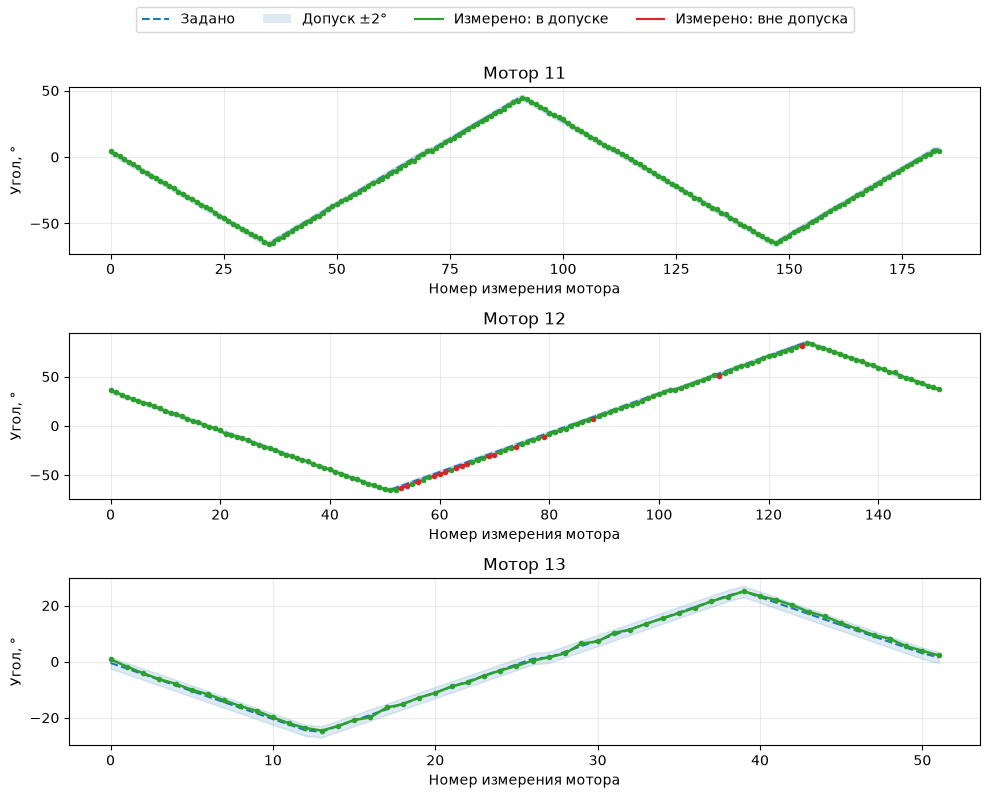

In [41]:
draw_leg(leg1, 1)

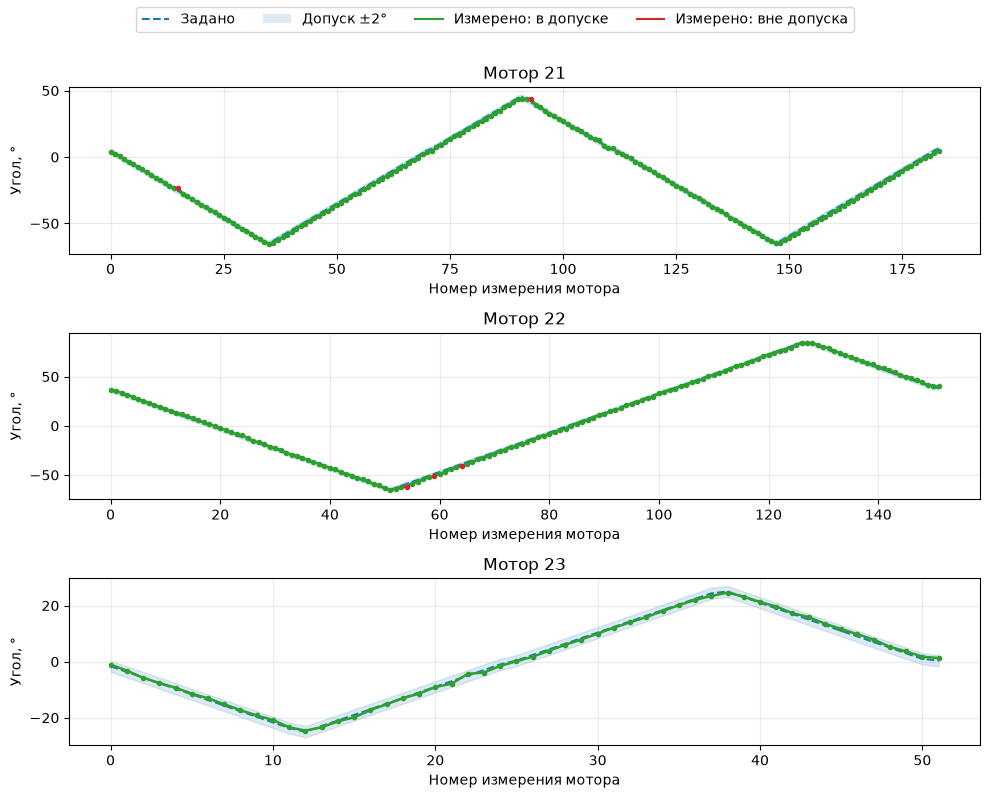

In [46]:
draw_leg(leg2, 2)

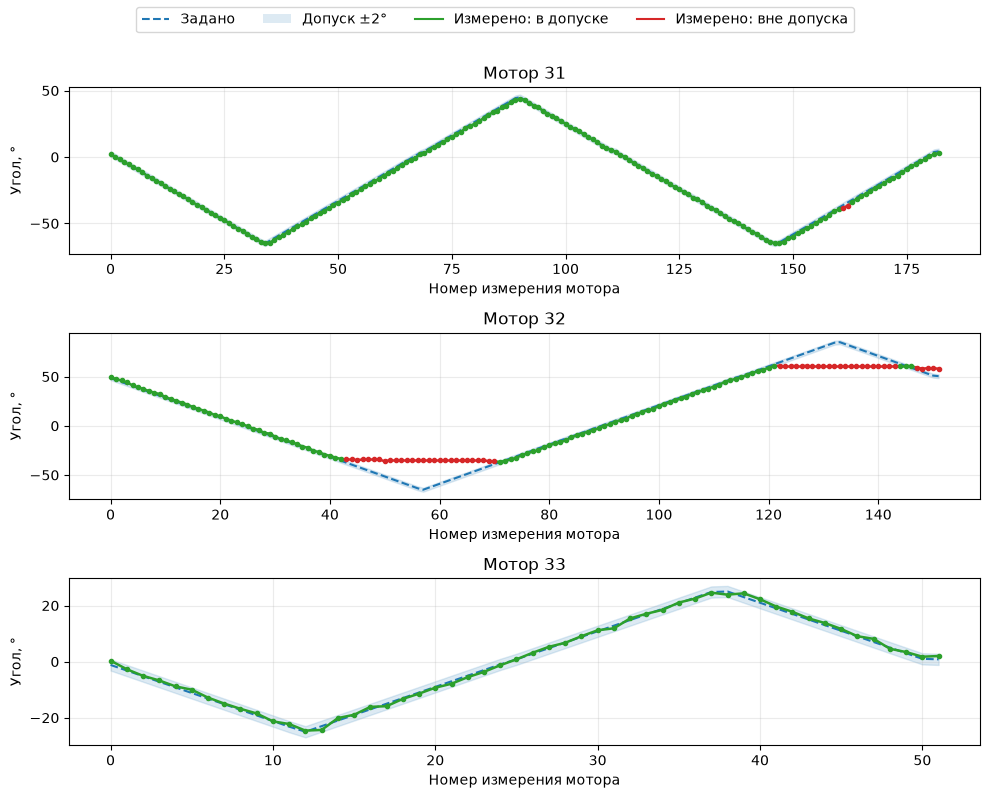

In [43]:
draw_leg(leg3, 3)

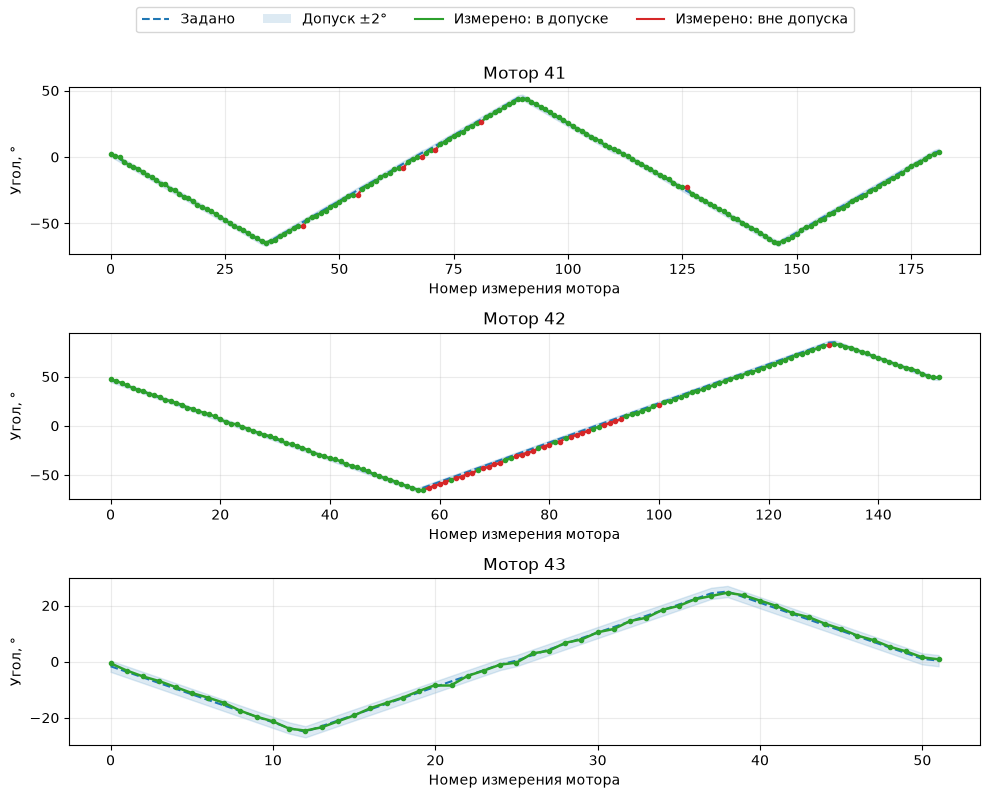

In [44]:
draw_leg(leg4, 4)